# LAB 04 — Text Classification

Chạy các cell theo thứ tự. Chỉ sửa phần cấu hình và ghi nhận kết quả thực tế vào các tệp Markdown.

## 1. Imports và cấu hình

Sửa đường dẫn dataset và hai tên cột trước khi chạy.

In [1]:
from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    precision_recall_fscore_support,
)
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

LAB_DIRECTORY_NAME = 'lab4'
DEFAULT_DATA_FILENAME = 'IMDB Dataset.csv'
DEFAULT_TEXT_COLUMN = 'review'
DEFAULT_LABEL_COLUMN = 'sentiment'
TEST_SIZE = 0.20
VALIDATION_SIZE = 0.20
RANDOM_STATE = 42
MAX_ITERATIONS = 1000
UNIGRAM_RANGE = (1, 1)
UNIGRAM_BIGRAM_RANGE = (1, 2)
WORD2VEC_VECTOR_SIZE = 100
WORD2VEC_WINDOW = 5
WORD2VEC_MIN_COUNT = 2
WORD2VEC_EPOCHS = 10
BINARY_THRESHOLDS = (0.5, 0.8)
TOP_FEATURE_COUNT = 10

LAB_DIRECTORY = Path.cwd().resolve()
if LAB_DIRECTORY.name != LAB_DIRECTORY_NAME:
    LAB_DIRECTORY = LAB_DIRECTORY / LAB_DIRECTORY_NAME
sys.path.insert(0, str(LAB_DIRECTORY))
from preprocessing import normalize_text, split_dataset

DATA_PATH = LAB_DIRECTORY / 'data' / DEFAULT_DATA_FILENAME  # TODO: sửa nếu cần.
TEXT_COLUMN = DEFAULT_TEXT_COLUMN  # TODO: sửa theo dataset.
LABEL_COLUMN = DEFAULT_LABEL_COLUMN  # TODO: sửa theo dataset.
POSITIVE_LABEL = None  # TODO: đặt nhãn positive cho bài toán nhị phân nếu cần.

candidate_models = {}
results_rows = []

## 2. Dataset inspection

Kiểm tra số mẫu, class distribution, missing values, trùng lặp và độ dài văn bản trước khi train.

,Số dòng ban đầu,Missing text,Missing labels,Duplicate texts,Số classes
0,50000,0,0,418,2


,Class,Count,Percentage
0,positive,24884,50.187568
1,negative,24698,49.812432


,count,mean,median,min,max
sentiment,,,,,
negative,24698,229.596607,174.0,4,1522
positive,24884,233.090620,172.0,10,2470


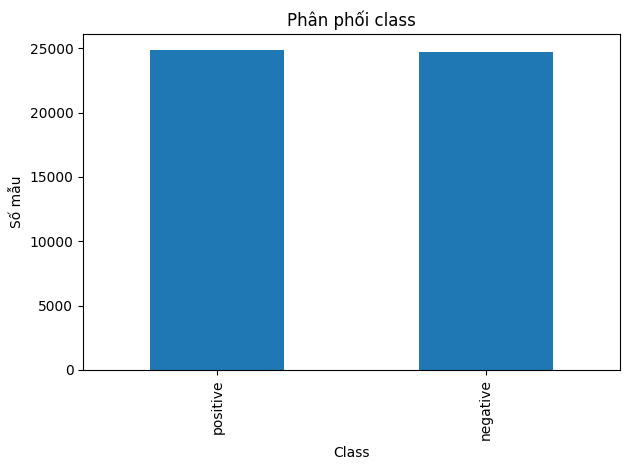

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(f'Không tìm thấy dataset: {DATA_PATH}')

raw_data = pd.read_csv(DATA_PATH)
required_columns = {TEXT_COLUMN, LABEL_COLUMN}
if not required_columns.issubset(raw_data.columns):
    raise KeyError(f'Thiếu cột. Cột hiện có: {list(raw_data.columns)}')

data = raw_data[[TEXT_COLUMN, LABEL_COLUMN]].copy()
quality_table = pd.DataFrame([{
    'Số dòng ban đầu': len(data),
    'Missing text': int(data[TEXT_COLUMN].isna().sum()),
    'Missing labels': int(data[LABEL_COLUMN].isna().sum()),
    'Duplicate texts': int(data[TEXT_COLUMN].duplicated().sum()),
    'Số classes': int(data[LABEL_COLUMN].nunique(dropna=True)),
}])
display(quality_table)

data = data.dropna(subset=[TEXT_COLUMN, LABEL_COLUMN]).copy()
data[TEXT_COLUMN] = data[TEXT_COLUMN].map(normalize_text)
data[LABEL_COLUMN] = data[LABEL_COLUMN].astype(str)
label_count_per_text = data.groupby(TEXT_COLUMN)[LABEL_COLUMN].nunique()
conflicting_texts = label_count_per_text[label_count_per_text > 1].index
data = data[~data[TEXT_COLUMN].isin(conflicting_texts)].copy()
data = data.drop_duplicates(subset=[TEXT_COLUMN]).reset_index(drop=True)
data['document_length'] = data[TEXT_COLUMN].str.split().str.len()

class_distribution = data[LABEL_COLUMN].value_counts().rename_axis('Class').reset_index(name='Count')
class_distribution['Percentage'] = 100 * class_distribution['Count'] / class_distribution['Count'].sum()
display(class_distribution)
display(data.groupby(LABEL_COLUMN)['document_length'].agg(['count', 'mean', 'median', 'min', 'max']))

class_distribution.set_index('Class')['Count'].plot(kind='bar', title='Phân phối class')
plt.ylabel('Số mẫu')
plt.tight_layout()
plt.savefig(LAB_DIRECTORY / 'class_distribution.png', dpi=160, bbox_inches='tight')
plt.show()

## 3. Train/validation/test split

Việc chia tập xảy ra trước khi TF-IDF/Word2Vec được fit để tránh data leakage.

In [3]:
texts = data[TEXT_COLUMN].tolist()
labels = data[LABEL_COLUMN].tolist()
(X_train, X_validation, X_test, y_train, y_validation, y_test) = split_dataset(
    texts, labels, TEST_SIZE, VALIDATION_SIZE, RANDOM_STATE
)
split_table = pd.DataFrame([
    {'Tập': 'Train', 'Số mẫu': len(X_train)},
    {'Tập': 'Validation', 'Số mẫu': len(X_validation)},
    {'Tập': 'Test', 'Số mẫu': len(X_test)},
])
display(split_table)

,Tập,Số mẫu
0,Train,29748
1,Validation,9917
2,Test,9917


## 4. Hàm đo lường

Dùng macro precision/recall/F1 để không bỏ qua lớp ít mẫu.

In [4]:
def calculate_classification_metrics(model, features, true_labels):
    """Tính accuracy cùng macro precision, recall và F1 cho một mô hình."""
    predicted_labels = model.predict(features)
    precision, recall, f1, _ = precision_recall_fscore_support(
        true_labels, predicted_labels, average='macro', zero_division=0
    )
    return {
        'accuracy': accuracy_score(true_labels, predicted_labels),
        'precision_macro': precision,
        'recall_macro': recall,
        'f1_macro': f1,
    }


def record_validation_result(name, representation, classifier, model, features, training_seconds, vocabulary_size, ngram_range):
    """Lưu metrics validation của một cấu hình vào bảng kết quả."""
    row = {
        'model': name,
        'representation': representation,
        'classifier': classifier,
        'split': 'validation',
        **calculate_classification_metrics(model, features, y_validation),
        'training_time_seconds': training_seconds,
        'vocabulary_size': vocabulary_size,
        'ngram_range': ngram_range,
        'notes': '',
    }
    results_rows.append(row)
    return row

## 5. Baseline — TF-IDF + Logistic Regression

In [5]:
tfidf_lr_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=UNIGRAM_RANGE)),
    ('classifier', LogisticRegression(max_iter=MAX_ITERATIONS, random_state=RANDOM_STATE)),
])
started_at = time.perf_counter()
tfidf_lr_pipeline.fit(X_train, y_train)
tfidf_lr_seconds = time.perf_counter() - started_at
tfidf_vocabulary_size = len(tfidf_lr_pipeline.named_steps['tfidf'].vocabulary_)
baseline_result = record_validation_result(
    'TF-IDF + Logistic Regression', 'TF-IDF unigram', 'Logistic Regression',
    tfidf_lr_pipeline, X_validation, tfidf_lr_seconds, tfidf_vocabulary_size, str(UNIGRAM_RANGE)
)
candidate_models['TF-IDF + Logistic Regression'] = (tfidf_lr_pipeline, X_validation, X_test)
display(pd.DataFrame([baseline_result]))

,model,representation,classifier,split,accuracy,precision_macro,recall_macro,f1_macro,training_time_seconds,vocabulary_size,ngram_range,notes
0,TF-IDF + Logistic Regression,TF-IDF unigram,Logistic Regression,validation,0.891802,0.89206,0.891755,0.891774,7.193804,82600,"(1, 1)",


## 6. Threshold cho binary classification

Chỉ chạy phần này khi dataset có đúng hai lớp.

In [6]:
def _calculate_threshold_row(true_labels, probabilities, threshold, positive_label, negative_label):
    """Tính metric nhị phân ứng với một ngưỡng quyết định."""
    threshold_predictions = np.where(probabilities >= threshold, positive_label, negative_label)
    precision, recall, f1, _ = precision_recall_fscore_support(
        true_labels, threshold_predictions, average='binary',
        pos_label=positive_label, zero_division=0
    )
    return {'Threshold': threshold, 'Precision': precision, 'Recall': recall, 'F1': f1}


classes = tfidf_lr_pipeline.named_steps['classifier'].classes_
if len(classes) == 2:
    positive_label = classes[1] if POSITIVE_LABEL is None else POSITIVE_LABEL
    positive_index = list(classes).index(positive_label)
    negative_label = classes[1 - positive_index]
    probabilities = tfidf_lr_pipeline.predict_proba(X_validation)[:, positive_index]
    threshold_rows = [
        _calculate_threshold_row(
            y_validation, probabilities, threshold, positive_label, negative_label
        )
        for threshold in BINARY_THRESHOLDS
    ]
    display(pd.DataFrame(threshold_rows))
else:
    print('Bỏ qua: đây không phải bài toán nhị phân.')

,Threshold,Precision,Recall,F1
0,0.5,0.882895,0.904360,0.893499
1,0.8,0.979081,0.573639,0.723426


## 7. Representation comparison — Average Word2Vec + Logistic Regression

Word2Vec chỉ học trên `X_train`; không đưa validation/test vào embedding training.

In [7]:
from gensim.models import Word2Vec


def _average_word2vec_document(text, keyed_vectors):
    """Tạo vector trung bình cho một văn bản; OOV-only nhận vector không."""
    token_vectors = [keyed_vectors[token] for token in text.split() if token in keyed_vectors]
    return (
        np.mean(token_vectors, axis=0)
        if token_vectors
        else np.zeros(keyed_vectors.vector_size, dtype=np.float32)
    )


def average_word2vec(text_values, keyed_vectors):
    """Biến mỗi văn bản thành trung bình vector của các token có trong vocabulary."""
    return np.vstack([
        _average_word2vec_document(text, keyed_vectors) for text in text_values
    ])

started_at = time.perf_counter()
word2vec_model = Word2Vec(
    sentences=[text.split() for text in X_train], vector_size=WORD2VEC_VECTOR_SIZE,
    window=WORD2VEC_WINDOW, min_count=WORD2VEC_MIN_COUNT, epochs=WORD2VEC_EPOCHS,
    workers=1, seed=RANDOM_STATE
)
X_train_w2v = average_word2vec(X_train, word2vec_model.wv)
X_validation_w2v = average_word2vec(X_validation, word2vec_model.wv)
X_test_w2v = average_word2vec(X_test, word2vec_model.wv)
w2v_lr = LogisticRegression(max_iter=MAX_ITERATIONS, random_state=RANDOM_STATE)
w2v_lr.fit(X_train_w2v, y_train)
w2v_lr_seconds = time.perf_counter() - started_at
w2v_result = record_validation_result(
    'Average Word2Vec + Logistic Regression', 'Average Word2Vec', 'Logistic Regression',
    w2v_lr, X_validation_w2v, w2v_lr_seconds, len(word2vec_model.wv), 'N/A'
)
candidate_models['Average Word2Vec + Logistic Regression'] = (w2v_lr, X_validation_w2v, X_test_w2v)
display(pd.DataFrame([w2v_result]))

,model,representation,classifier,split,accuracy,precision_macro,recall_macro,f1_macro,training_time_seconds,vocabulary_size,ngram_range,notes
0,Average Word2Vec + Logistic Regression,Average Word2Vec,Logistic Regression,validation,0.829182,0.829186,0.829173,0.829177,148.374256,111841,N/A,


## 8. N-gram features — unigram + bigram

So sánh vocabulary size, F1 và thời gian với baseline unigram.

In [8]:
tfidf_bigram_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=UNIGRAM_BIGRAM_RANGE)),
    ('classifier', LogisticRegression(max_iter=MAX_ITERATIONS, random_state=RANDOM_STATE)),
])
started_at = time.perf_counter()
tfidf_bigram_pipeline.fit(X_train, y_train)
bigram_seconds = time.perf_counter() - started_at
bigram_vocabulary_size = len(tfidf_bigram_pipeline.named_steps['tfidf'].vocabulary_)
bigram_result = record_validation_result(
    'TF-IDF unigram + bigram + Logistic Regression', 'TF-IDF unigram + bigram',
    'Logistic Regression', tfidf_bigram_pipeline, X_validation, bigram_seconds,
    bigram_vocabulary_size, str(UNIGRAM_BIGRAM_RANGE)
)
candidate_models['TF-IDF unigram + bigram + Logistic Regression'] = (tfidf_bigram_pipeline, X_validation, X_test)
display(pd.DataFrame([baseline_result, bigram_result]))

,model,representation,classifier,split,accuracy,precision_macro,recall_macro,f1_macro,training_time_seconds,vocabulary_size,ngram_range,notes
0,TF-IDF + Logistic Regression,TF-IDF unigram,Logistic Regression,validation,0.891802,0.892060,0.891755,0.891774,7.193804,82600,"(1, 1)",
1,TF-IDF unigram + bigram + Logistic Regression,TF-IDF unigram + bigram,Logistic Regression,validation,0.891197,0.891523,0.891144,0.891163,38.709727,1725370,"(1, 2)",


## 9. Optional model — TF-IDF + Linear SVM

In [9]:
tfidf_svm_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=UNIGRAM_RANGE)),
    ('classifier', LinearSVC(random_state=RANDOM_STATE)),
])
started_at = time.perf_counter()
tfidf_svm_pipeline.fit(X_train, y_train)
svm_seconds = time.perf_counter() - started_at
svm_vocabulary_size = len(tfidf_svm_pipeline.named_steps['tfidf'].vocabulary_)
svm_result = record_validation_result(
    'TF-IDF + Linear SVM', 'TF-IDF unigram', 'Linear SVM', tfidf_svm_pipeline,
    X_validation, svm_seconds, svm_vocabulary_size, str(UNIGRAM_RANGE)
)
candidate_models['TF-IDF + Linear SVM'] = (tfidf_svm_pipeline, X_validation, X_test)
display(pd.DataFrame([svm_result]))

,model,representation,classifier,split,accuracy,precision_macro,recall_macro,f1_macro,training_time_seconds,vocabulary_size,ngram_range,notes
0,TF-IDF + Linear SVM,TF-IDF unigram,Linear SVM,validation,0.898155,0.898324,0.898117,0.898136,5.910043,82600,"(1, 1)",


## 10. Chọn model bằng validation và đánh giá test

Chỉ dùng test một lần, sau khi đã chọn model có macro F1 tốt nhất trên validation.

In [10]:
validation_table = pd.DataFrame(results_rows).sort_values('f1_macro', ascending=False)
display(validation_table)
best_model_name = validation_table.iloc[0]['model']
best_model, _, best_test_features = candidate_models[best_model_name]
best_test_predictions = best_model.predict(best_test_features)
test_metrics = calculate_classification_metrics(best_model, best_test_features, y_test)
test_result = {
    'model': best_model_name, 'representation': validation_table.iloc[0]['representation'],
    'classifier': validation_table.iloc[0]['classifier'], 'split': 'test',
    **test_metrics, 'training_time_seconds': np.nan, 'vocabulary_size': np.nan,
    'ngram_range': '', 'notes': 'Chọn theo validation macro F1.',
}
results_rows.append(test_result)
display(pd.DataFrame([test_result]))

,model,representation,classifier,split,accuracy,precision_macro,recall_macro,f1_macro,training_time_seconds,vocabulary_size,ngram_range,notes
3,TF-IDF + Linear SVM,TF-IDF unigram,Linear SVM,validation,0.898155,0.898324,0.898117,0.898136,5.910043,82600,"(1, 1)",
0,TF-IDF + Logistic Regression,TF-IDF unigram,Logistic Regression,validation,0.891802,0.892060,0.891755,0.891774,7.193804,82600,"(1, 1)",
2,TF-IDF unigram + bigram + Logistic Regression,TF-IDF unigram + bigram,Logistic Regression,validation,0.891197,0.891523,0.891144,0.891163,38.709727,1725370,"(1, 2)",
1,Average Word2Vec + Logistic Regression,Average Word2Vec,Logistic Regression,validation,0.829182,0.829186,0.829173,0.829177,148.374256,111841,N/A,


,model,representation,classifier,split,accuracy,precision_macro,recall_macro,f1_macro,training_time_seconds,vocabulary_size,ngram_range,notes
0,TF-IDF + Linear SVM,TF-IDF unigram,Linear SVM,test,0.89755,0.897638,0.897523,0.897538,NaN,NaN,,Chọn theo validation macro F1.


## 11. Confusion matrix, error analysis và model weights

,negative,positive
negative,4398,542
positive,474,4503


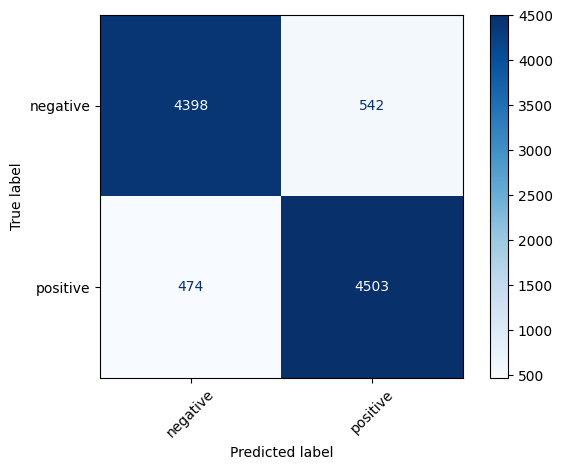

,Text,True label,Predicted label
0,my wife and i watched this after dvr'ing it of...,negative,negative
1,i was surprised how much i enjoyed this. sure ...,positive,positive
2,such a delightful movie! very heart warming. o...,positive,positive


,Text,True label,Predicted label
17,i see this movie as a poor tribute to the old ...,negative,positive
24,despite being a huge fan of fred astaire and g...,negative,positive
32,"i know that full moon, or any other film studi...",negative,positive


Top features cho class: positive


,Feature,Weight
31454,great,8.060252
25198,excellent,6.694635
7738,best,5.483192
54398,perfect,4.991726
81054,wonderful,4.830621
3218,amazing,4.390529
43650,loved,4.329276
26384,favorite,4.214190
43643,love,4.150757
28953,fun,4.075226


Top features cho class: negative


,Feature,Weight
81281,worst,-9.805031
5993,bad,-8.760157
5729,awful,-7.611309
9349,boring,-6.785027
79636,waste,-6.728464
72936,terrible,-6.054570
56182,poor,-5.732627
50925,nothing,-5.557116
81264,worse,-5.126329
50608,no,-4.646075


In [11]:
label_order = sorted(pd.Series(y_test).unique())
test_matrix = confusion_matrix(y_test, best_test_predictions, labels=label_order)
display(pd.DataFrame(test_matrix, index=label_order, columns=label_order))
ConfusionMatrixDisplay(test_matrix, display_labels=label_order).plot(cmap='Blues', xticks_rotation=45)
plt.tight_layout()
plt.savefig(LAB_DIRECTORY / 'confusion_matrix.png', dpi=160, bbox_inches='tight')
plt.show()

test_examples = pd.DataFrame({'Text': X_test, 'True label': y_test, 'Predicted label': best_test_predictions})
display(test_examples[test_examples['True label'] == test_examples['Predicted label']].head(3))
display(test_examples[test_examples['True label'] != test_examples['Predicted label']].head(3))

lr_classifier = tfidf_lr_pipeline.named_steps['classifier']
feature_names = tfidf_lr_pipeline.named_steps['tfidf'].get_feature_names_out()
if len(lr_classifier.classes_) == 2:
    positive_class = lr_classifier.classes_[1]
    negative_class = lr_classifier.classes_[0]
    feature_weights = pd.DataFrame({'Feature': feature_names, 'Weight': lr_classifier.coef_[0]})
    print(f'Top features cho class: {positive_class}')
    display(feature_weights.nlargest(TOP_FEATURE_COUNT, 'Weight'))
    print(f'Top features cho class: {negative_class}')
    display(feature_weights.nsmallest(TOP_FEATURE_COUNT, 'Weight'))
else:
    feature_weight_table = pd.DataFrame(
        lr_classifier.coef_.T, index=feature_names, columns=lr_classifier.classes_
    )
    for class_label in lr_classifier.classes_:
        print(f'Top features cho class: {class_label}')
        display(feature_weight_table[[class_label]].nlargest(TOP_FEATURE_COUNT, class_label))

## 12. Word order và lưu kết quả

Ghi nhận nhận xét về `not good` trong `reflection.md`.

In [12]:
ORDER_EXAMPLES = ['not good', 'good not']
unigram_vectors = TfidfVectorizer(ngram_range=UNIGRAM_RANGE).fit_transform(ORDER_EXAMPLES)
bigram_vectors = TfidfVectorizer(ngram_range=UNIGRAM_BIGRAM_RANGE).fit_transform(ORDER_EXAMPLES)
average_vectors = average_word2vec(ORDER_EXAMPLES, word2vec_model.wv)
order_table = pd.DataFrame([{
    'Representation': 'TF-IDF unigram',
    'Cosine similarity': cosine_similarity(unigram_vectors[0], unigram_vectors[1])[0, 0],
}, {
    'Representation': 'TF-IDF unigram + bigram',
    'Cosine similarity': cosine_similarity(bigram_vectors[0], bigram_vectors[1])[0, 0],
}, {
    'Representation': 'Average Word2Vec',
    'Cosine similarity': cosine_similarity(average_vectors[0].reshape(1, -1), average_vectors[1].reshape(1, -1))[0, 0],
}])
display(order_table)

results_path = LAB_DIRECTORY / 'results.csv'
pd.DataFrame(results_rows).to_csv(results_path, index=False)
print(f'Đã lưu: {results_path}')

,Representation,Cosine similarity
0,TF-IDF unigram,1.000000
1,TF-IDF unigram + bigram,0.503103
2,Average Word2Vec,1.000000


Đã lưu: G:\My Drive\Documents\NLP\lab4\results.csv
